# Interfaces: what a slab of the lattice sees

Notebook 03 extracted a permittivity and a permeability of the rod lattice from its bulk response, and they give the Bloch wavenumber. Whether they also give the reflection of a slab is a separate question (notebook 01, section 5), and it is the one that matters in practice, because effective parameters of metamaterials are almost always *retrieved* from the reflection and transmission of a slab. This notebook computes slabs of the lattice exactly and compares.

## What this notebook shows

- An exact solver for a slab of $N$ line arrays of rods, with checks.
- Retrieval at normal incidence returns the Bloch index, in agreement with the bulk calculation, and an admittance that is a property of the slab and its termination.
- TM at low frequency, where nothing resonates: three values of $\mu-1$ for one lattice, positive of order $\omega^2$ (the magnetic dipole of the rod), zero to order $\omega^2$ (the bulk expansion), and negative of order $\omega^2$ (the slab). The third is the cut-dependent artifact of notebook 01, and it obeys a $(qa)^2$ law.
- TE through the magnetic resonance: the retrieved permittivity has an antiresonance, with a negative imaginary part when the rods are lossy, while the bulk permittivity is featureless and passive. Just below the resonance the bulk parameters give little more than half of the reflection of a slab.
- One picture for both: the ratio of the Bloch impedance to the bulk impedance as a function of $qa$, which goes down when the rods act as a lumped electric response and up when they act as a lumped magnetic one.
- TE at low frequency: a static surface layer, visible as a $1/N$ dependence of the retrieved parameters, which extrapolate to the bulk values.

## Conventions

As in notebooks 02 and 03: $e^{-i\omega t}$, period $a=1$, $f=a/\lambda_0$, rod radius $R=0.3$, TM is $\mathbf E$ along the rods ($u=E_z$), TE is $\mathbf H$ along the rods ($u=H_z$). Slabs are $N$ layers thick with faces half a period outside the first and last rows of rods, and light is incident along a lattice axis. The interface admittance $y$ is defined for the field $u$: a half-space reflects $u$ with $r=(1-y)/(1+y)$, where $y=n/\mu$ for TM and $y=n/\varepsilon$ for TE. The wave impedance $z=E/H$ is $1/y$ for TM and $y$ for TE.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

# Figure style shared by every notebook in notebooks/spatial_dispersion (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name

In [2]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd()))          # rodlattice.py sits next to this notebook
import rodlattice as rl
from scipy.special import jv

TWO_PI = 2 * np.pi
R = 0.3
FILL = np.pi * R**2

## 1. The slab solver

A slab is $N$ line arrays of rods at $x=0,a,\dots,(N-1)a$, periodic along $y$. A plane wave with transverse wavenumber $k_y$ arrives from the left. Each array has one set of multipole coefficients $b^{(j)}_l$, and

$$b^{(j)}_l=t_l\Big[e^{ik_xx_j}\,i^le^{-il\varphi_0}+\sum_mG^{\rm 1D}_{l-m}b^{(j)}_m+\sum_{i\neq j}\sum_mT_{l-m}(x_i-x_j)\,b^{(i)}_m\Big].$$

$G^{\rm 1D}$ are the lattice sums of one line array (notebook 02). $T_n(X)$ carries the waves of an array displaced by $X$; it is a sum over diffraction orders $p$ with factors $e^{ik_{x,p}|X|}$, which converges exponentially because all orders but one are evanescent between rows. The same plane-wave form gives the reflected and transmitted amplitudes from the $b^{(j)}_l$. `rodlattice.slab` solves this system.

In [3]:
def homog_slab(k0, d, n, y):
    """(r, t) of the field u for a homogeneous slab of index n and interface admittance y, normal incidence."""
    r01 = (1 - y) / (1 + y); ph = np.exp(1j * n * k0 * d)
    return r01 * (1 - ph**2) / (1 - r01**2 * ph**2), (1 - r01**2) * ph / (1 - r01**2 * ph**2)


print("flux balance and reciprocity, lossless rods (eps_r = 12), oblique incidence, up to the first diffraction orders:")
worst_flux, worst_rec = 0.0, 0.0
for pol in ("TM", "TE"):
    for f, ky, N in [(0.25, 0.0, 1), (0.33, 0.7, 4), (0.45, 1.5, 6), (0.8, 0.9, 3)]:
        k0 = TWO_PI * f
        r, t, (rp, tp, kxp), _ = rl.slab(k0, ky, N, R, 12.0, pol, M=5)
        prop = np.abs(kxp.imag) < 1e-12
        flux = ((np.abs(rp[prop]) ** 2 + np.abs(tp[prop]) ** 2) * kxp[prop].real).sum() / kxp[2].real
        t_rev = rl.slab(k0, -ky, N, R, 12.0, pol, M=5)[1]
        worst_flux, worst_rec = max(worst_flux, abs(flux - 1)), max(worst_rec, abs(t - t_rev))
        print(f"  {pol}, f = {f}, ky = {ky}, N = {N}: {prop.sum()} propagating orders, R + T - 1 = {flux - 1:+.1e}")
check("flux balance over all propagating orders", worst_flux, 1e-10)
check("reciprocity t(ky) = t(-ky)", worst_rec, 1e-10)

print("long-wavelength limit, f = 0.005, N = 8, against a homogeneous slab with the static permittivity:")
k0 = TWO_PI * 0.005
for pol, eps_st in (("TM", 1 + FILL * 11.0), ("TE", 1.6301245)):
    r, t = rl.slab(k0, 0.0, 8, R, 12.0, pol)[:2]
    n = np.sqrt(eps_st)
    rh, th = homog_slab(k0, 8.0, n, n if pol == "TM" else 1 / n)
    check(f"{pol}: |r - r_hom| + |t - t_hom|", abs(r - rh) + abs(t - th), 1e-3)

flux balance and reciprocity, lossless rods (eps_r = 12), oblique incidence, up to the first diffraction orders:
  TM, f = 0.25, ky = 0.0, N = 1: 1 propagating orders, R + T - 1 = -6.7e-16
  TM, f = 0.33, ky = 0.7, N = 4: 1 propagating orders, R + T - 1 = +1.1e-15
  TM, f = 0.45, ky = 1.5, N = 6: 1 propagating orders, R + T - 1 = -7.8e-16
  TM, f = 0.8, ky = 0.9, N = 3: 1 propagating orders, R + T - 1 = -1.1e-14
  TE, f = 0.25, ky = 0.0, N = 1: 1 propagating orders, R + T - 1 = +0.0e+00
  TE, f = 0.33, ky = 0.7, N = 4: 1 propagating orders, R + T - 1 = +1.1e-15
  TE, f = 0.45, ky = 1.5, N = 6: 1 propagating orders, R + T - 1 = -1.4e-15
  TE, f = 0.8, ky = 0.9, N = 3: 1 propagating orders, R + T - 1 = +1.1e-15
PASS  flux balance over all propagating orders: got 1.05471e-14, target 0, |diff| 1.05e-14 <= 1e-10
PASS  reciprocity t(ky) = t(-ky): got 1.23453e-14, target 0, |diff| 1.23e-14 <= 1e-10
long-wavelength limit, f = 0.005, N = 8, against a homogeneous slab with the static permittivit

## 2. Retrieval, and the bulk parameters to compare with

From $r$ and $t$ of a slab of thickness $d=Na$ the standard inversion (Smith and coworkers) gives the admittance and the index of the homogeneous slab with the same response,

$$y^2=\frac{(1-r)^2-t^2}{(1+r)^2-t^2},\qquad e^{ink_0d}=\frac{t}{1-r\,\frac{1-y}{1+y}},$$

and then $\varepsilon=ny$, $\mu=n/y$ for TM and $\varepsilon=n/y$, $\mu=ny$ for TE. The sign of $y$ is fixed by a positive real part (or decay, in a gap or with loss) and the branch of the logarithm by the Bloch wavenumber, which is known here from the bulk calculation.

The bulk parameters are those of notebook 03: $\varepsilon(\omega)=\varepsilon^T(\omega,0)$ and $\mu(\omega)=1/(1-k_0^2c_2)$, with $c_2$ the coefficient of $k^2$ of the transverse permittivity along the direction of propagation, here $\Gamma X$. They are called "bulk" below. The corresponding admittance is $y_{\rm bulk}=\sqrt{\varepsilon/\mu}$ for TM and $\sqrt{\mu/\varepsilon}$ for TE.

In [4]:
def eps_T(pol, k0, kap, eps, M=4):
    """Transverse eps(w, k) for k = (kap, 0)."""
    e = rl.driven(k0, (kap, 0.0), R, eps, pol, M=M)[0]
    return e if pol == "TM" else e[1, 1]


def bulk_parameters(pol, f, eps, rho=0.1, n=12):
    """(eps, mu) from the expansion of eps_T(w, k) along Gamma X (Cauchy integral on |k| = rho)."""
    k0 = TWO_PI * f
    th = (np.arange(n) + 0.5) * TWO_PI / n
    vals = np.array([eps_T(pol, k0, rho * np.exp(1j * t), eps) for t in th])
    c0, c2 = vals.mean(), (vals * np.exp(-2j * th)).mean() / rho**2
    return c0, 1 / (1 - k0**2 * c2)


def bloch_index(pol, f, eps, guess):
    """Exact Bloch index along Gamma X from k^2 = k0^2 eps_T(w, k) (secant iteration; complex in a gap or with loss)."""
    k0 = TWO_PI * f
    g = lambda kap: k0**2 * eps_T(pol, k0, kap, eps) - kap**2
    k1, k2 = guess * k0, guess * k0 * 1.001 + 1e-4
    g1, g2 = g(k1), g(k2)
    for _ in range(60):
        k3 = k2 - g2 * (k2 - k1) / (g2 - g1)
        if abs(k3 - k2) < 1e-12:
            return (k3 if k3.imag >= -1e-9 else -k3) / k0
        k1, g1, k2, g2 = k2, g2, k3, g(k3)
    return np.nan


def retrieve(r, t, k0, d, pol, n_ref):
    """(n, y, eps, mu) of the homogeneous slab of thickness d with the same r and t of the field u."""
    y = np.sqrt(((1 - r) ** 2 - t**2) / ((1 + r) ** 2 - t**2) + 0j)
    if y.real < 0:
        y = -y
    ph = t / (1 - r * (1 - y) / (1 + y))
    if abs(ph) > 1 + 1e-9:                               # the other root is the decaying one
        y = -y; ph = t / (1 - r * (1 - y) / (1 + y))
    n = (np.angle(ph) - 1j * np.log(abs(ph))) / (k0 * d)
    n += np.round((n_ref.real - n.real) * k0 * d / TWO_PI) * TWO_PI / (k0 * d)
    return (n, y, n * y, n / y) if pol == "TM" else (n, y, n / y, n * y)


def bulk_ny(pol, eps_b, mu_b):
    n = np.sqrt(eps_b * mu_b + 0j)
    n = n if n.imag >= -1e-12 else -n
    return n, (n / mu_b if pol == "TM" else n / eps_b)


# a first look: the retrieved index is the Bloch index
print("retrieved index against the Bloch index of the bulk calculation (lossless rods):")
worst = 0.0
for pol, eps, f in [("TM", 12.0, 0.10), ("TE", 12.0, 0.20), ("TE", 100.0, 0.10), ("TE", 100.0, 0.12)]:
    nB = bloch_index(pol, f, eps, bulk_ny(pol, *bulk_parameters(pol, f, eps))[0])
    ns = [retrieve(*rl.slab(TWO_PI * f, 0.0, N, R, eps, pol, M=5)[:2], TWO_PI * f, N, pol, nB)[0].real for N in (1, 4, 16)]
    worst = max(worst, abs(ns[-1] / nB.real - 1))
    print(f"  {pol}, eps_r = {eps:g}, f = {f}: Bloch {nB.real:.5f}, retrieved for N = 1, 4, 16: {np.round(ns, 5)}")
check("retrieved index at N = 16 equals the Bloch index (relative)", worst, 5e-4)

retrieved index against the Bloch index of the bulk calculation (lossless rods):
  TM, eps_r = 12, f = 0.1: Bloch 2.07528, retrieved for N = 1, 4, 16: [2.07493 2.07519 2.07526]
  TE, eps_r = 12, f = 0.2: Bloch 1.31977, retrieved for N = 1, 4, 16: [1.32047 1.31994 1.31982]
  TE, eps_r = 100, f = 0.1: Bloch 1.51398, retrieved for N = 1, 4, 16: [1.5176  1.51488 1.51421]
  TE, eps_r = 100, f = 0.12: Bloch 2.00013, retrieved for N = 1, 4, 16: [2.00004 2.00012 2.00012]
PASS  retrieved index at N = 16 equals the Bloch index (relative): got 0.000151086, target 0, |diff| 1.51e-04 <= 5e-04


The index is not in question: the retrieved index converges to the Bloch index as the slab gets thicker, and one layer is already within a few parts in a thousand (the correction falls like $1/N$ in TE, section 6). The rest of the notebook is about the admittance.

## 3. TM at low frequency: three permeabilities

Take $\varepsilon_r=12$ and frequencies far below any resonance. Three procedures assign a permeability to this lattice.

1. **Magnetic dipole of the rod.** The loop estimate of notebook 03, $\mu-1\approx k_0^2\eta(\varepsilon_r-1)R^2/8$ with $\eta=\pi R^2/a^2$ the filling fraction, positive and of order $\omega^2$. Effective-medium formulas built on the $m=\pm1$ scattering coefficient are of this kind.
2. **Bulk expansion.** $\mu-1=k_0^2\beta/(1-k_0^2\beta)$ with $\beta\propto\omega^2$: zero to order $\omega^2$ (notebook 03, section 6).
3. **Slab.** $\mu=n/y$ from the retrieval, with the faces of the slab half a period outside the outer rows of rods.

     f     q a     n_Bloch   y_ret(N=1)  y_ret(N=16)   mu_loop-1   mu_bulk-1    mu_ret-1   (mu_ret-1)/f^2   (y_ret/y_bulk-1)/(qa)^2
  0.01   0.127    2.02778     2.02930     2.02930     0.00014     0.00000    -0.00075        -7.481            0.0460
  0.02   0.255    2.02907     2.03517     2.03519     0.00055     0.00000    -0.00301        -7.515            0.0462
  0.03   0.383    2.03123     2.04513     2.04530     0.00124     0.00001    -0.00682        -7.574            0.0467
  0.05   0.640    2.03831     2.07854     2.07857     0.00345     0.00011    -0.01942        -7.766            0.0484
  0.08   1.034    2.05665     2.17149     2.17136     0.00884     0.00076    -0.05301        -8.283            0.0530
  0.10   1.304    2.07528     2.27593     2.27659     0.01381     0.00205    -0.08832        -8.832            0.0583
  0.13   1.730    2.11746     2.55558     2.55870     0.02334     0.00706    -0.17154       -10.150            0.0724
  0.15   2.038    2.16187     2.92809     

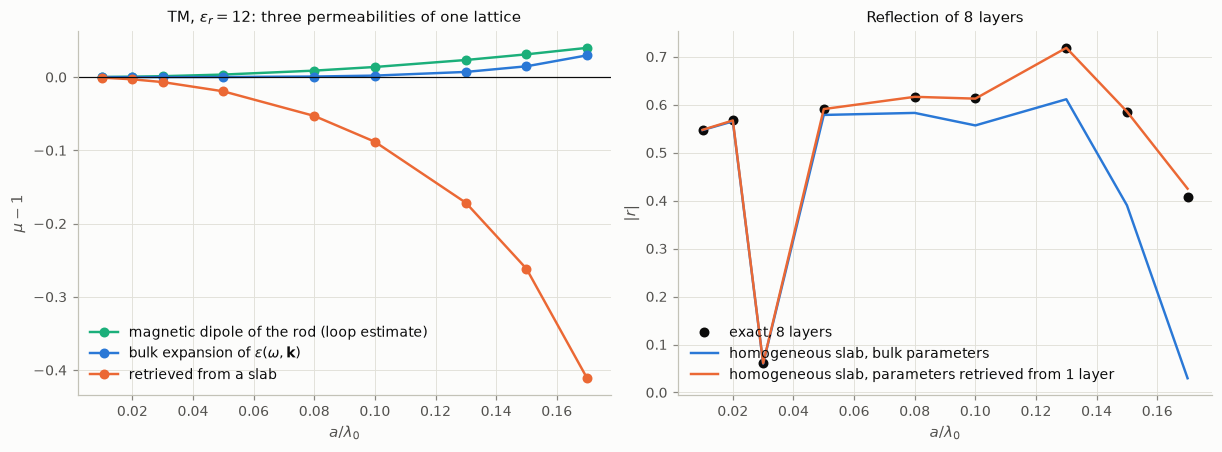

error of |r| for 8 layers: bulk parameters up to 0.379, one-layer parameters up to 0.0167
  f:                0.01    0.02    0.03    0.05    0.08    0.10    0.13    0.15    0.17
  bulk error:      0.000   0.002   0.001   0.012   0.033   0.056   0.107   0.194   0.379
  1-layer error:   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.002   0.017
PASS  parameters retrieved from one layer predict the reflection of eight (largest error of |r|): got 0.0166699, target 0, |diff| 1.67e-02 <= 2e-02


In [5]:
def tm_low_frequency(F, Ns=(1, 4, 16)):
    rows = []
    for f in F:
        k0 = TWO_PI * f
        eb, mb = bulk_parameters("TM", f, 12.0, rho=0.2)
        nb, yb = bulk_ny("TM", eb, mb)
        nB = bloch_index("TM", f, 12.0, nb)
        ret = [retrieve(*rl.slab(k0, 0.0, N, R, 12.0, "TM", M=5)[:2], k0, N, "TM", nB) for N in Ns]
        r8 = rl.slab(k0, 0.0, 8, R, 12.0, "TM", M=5)[0]
        rows.append(dict(f=f, qa=nB.real * k0, nB=nB.real, mu_bulk=mb.real, y_bulk=yb.real, n_ret=[x[0].real for x in ret],
                         y_ret=[x[1].real for x in ret], r8=abs(r8), r8_bulk=abs(homog_slab(k0, 8.0, nb, yb)[0]),
                         r8_ret=abs(homog_slab(k0, 8.0, ret[0][0], ret[0][1])[0])))
    return rows


FTM = np.array([0.01, 0.02, 0.03, 0.05, 0.08, 0.10, 0.13, 0.15, 0.17])
tm = tm_low_frequency(FTM)
col = lambda key: np.array([row[key] for row in tm])
mu_loop = 1 + (TWO_PI * FTM) ** 2 * FILL * 11.0 * R**2 / 8
mu_ret = col("n_ret")[:, 0] / col("y_ret")[:, 0]
print("     f     q a     n_Bloch   y_ret(N=1)  y_ret(N=16)   mu_loop-1   mu_bulk-1    mu_ret-1   (mu_ret-1)/f^2   (y_ret/y_bulk-1)/(qa)^2")
for i, row in enumerate(tm):
    print(f"{row['f']:6.2f} {row['qa']:7.3f} {row['nB']:10.5f} {row['y_ret'][0]:11.5f} {row['y_ret'][2]:11.5f} {mu_loop[i] - 1:11.5f} {row['mu_bulk'] - 1:11.5f} "
          f"{mu_ret[i] - 1:11.5f} {(mu_ret[i] - 1) / row['f']**2:13.3f} {(row['y_ret'][0] / row['y_bulk'] - 1) / row['qa']**2:17.4f}")
spread = np.abs(col("y_ret")[:, 2] / col("y_ret")[:, 0] - 1)
print(f"relative difference of the admittance retrieved from 1 and from 16 layers: {spread[FTM <= 0.1].max():.1e} up to f = 0.10, {spread.max():.1e} over the whole range")
check("the retrieved admittance does not depend on N up to f = 0.10 (relative spread between N = 1 and 16)", spread[FTM <= 0.1].max(), 1e-3)
check("slab: mu - 1 is negative and proportional to f^2 (ratio of (mu - 1)/f^2 at the two lowest frequencies)", (mu_ret[1] - 1) / FTM[1] ** 2 / ((mu_ret[0] - 1) / FTM[0] ** 2), 0.02, 1.0)
assert (mu_ret < 1).all() and (mu_loop > 1).all()
check("bulk: mu - 1 is of order f^4 (exponent between the two lowest frequencies)", np.log((col("mu_bulk")[1] - 1) / (col("mu_bulk")[0] - 1)) / np.log(2), 0.1, 4.0)
C_TM = (tm[0]["y_ret"][0] / tm[0]["y_bulk"] - 1) / tm[0]["qa"] ** 2
check("y_ret / y_bulk - 1 = c (qa)^2 at low frequency: c at f = 0.01 against f = 0.02", (tm[1]["y_ret"][0] / tm[1]["y_bulk"] - 1) / tm[1]["qa"] ** 2 / C_TM, 0.02, 1.0)
print(f"coefficient c = {C_TM:.4f}; a lumped shunt element cut midway between elements would give 1/8")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ax = axs[0]
ax.plot(FTM, mu_loop - 1, "o-", color=CAT[2], label="magnetic dipole of the rod (loop estimate)")
ax.plot(FTM, col("mu_bulk") - 1, "o-", color=CAT[0], label=r"bulk expansion of $\varepsilon(\omega,\mathbf{k})$")
ax.plot(FTM, mu_ret - 1, "o-", color=CAT[1], label="retrieved from a slab")
ax.axhline(0, color=INK, lw=0.8)
ax.set(xlabel=r"$a/\lambda_0$", ylabel=r"$\mu-1$", title=r"TM, $\varepsilon_r=12$: three permeabilities of one lattice"); ax.legend(loc="lower left")
ax = axs[1]
ax.plot(FTM, col("r8"), "o", color=INK, label="exact, 8 layers")
ax.plot(FTM, col("r8_bulk"), "-", color=CAT[0], label="homogeneous slab, bulk parameters")
ax.plot(FTM, col("r8_ret"), "-", color=CAT[1], label="homogeneous slab, parameters retrieved from 1 layer")
ax.set(xlabel=r"$a/\lambda_0$", ylabel=r"$|r|$", title="Reflection of 8 layers"); ax.legend(loc="lower left")
plt.show()
err_bulk, err_ret = np.abs(col("r8_bulk") - col("r8")), np.abs(col("r8_ret") - col("r8"))
print(f"error of |r| for 8 layers: bulk parameters up to {err_bulk.max():.3f}, one-layer parameters up to {err_ret.max():.4f}")
print("  f:              " + "  ".join(f"{f:6.2f}" for f in FTM))
print("  bulk error:     " + "  ".join(f"{e:6.3f}" for e in err_bulk))
print("  1-layer error:  " + "  ".join(f"{e:6.3f}" for e in err_ret))
check("parameters retrieved from one layer predict the reflection of eight (largest error of |r|)", err_ret.max(), 0.02)
assert err_bulk.max() > 5 * err_ret.max()

All three agree on the index, and they disagree on the sign of $\mu-1$. The slab's value is *diamagnetic*, proportional to $\omega^2$, the same for one layer and for sixteen (to the printed spread, which grows toward the band edge), and it predicts the reflection of a thick slab to the printed accuracy, which the bulk parameters do not. It is nevertheless not a magnetic response of anything. The printed ratio shows what it is: the admittance of the slab exceeds the bulk admittance by $c\,(qa)^2$, where $q$ is the Bloch wavenumber. That is the Bloch admittance of a periodic medium cut between its polarizable elements, the first case of notebook 01, section 5.2. In circuit language the rods are a shunt capacitance concentrated at the center of the cell, the cut is the T section, and the lumped limit would give $c=1/8$. The computed $c$ is 2.7 times smaller. That the rods are extended goes in this direction, but the factor was not derived.

Two remarks. The magnetic dipole of the rod, which one might have expected to see, appears in neither the bulk expansion nor the slab at this order. And the bulk parameters are not wrong about the interface in the limit $qa\to0$; they are wrong at order $(qa)^2$, and $q$ is the wavenumber in the lattice, which is large in this polarization.

## 4. TE through the magnetic resonance

Now the case that looks like a metamaterial: TE, $\varepsilon_r=100$, with a little loss, $\varepsilon_r=100(1+0.02i)$, so that all quantities are smooth through the resonance and the sign of imaginary parts can be read. Retrieval from one layer and from four, against the bulk parameters.

sweep of 101 frequencies: 2 s
absorption of the 8-layer slab, 1 - |r|^2 - |t|^2: between 0.0064 and 0.886


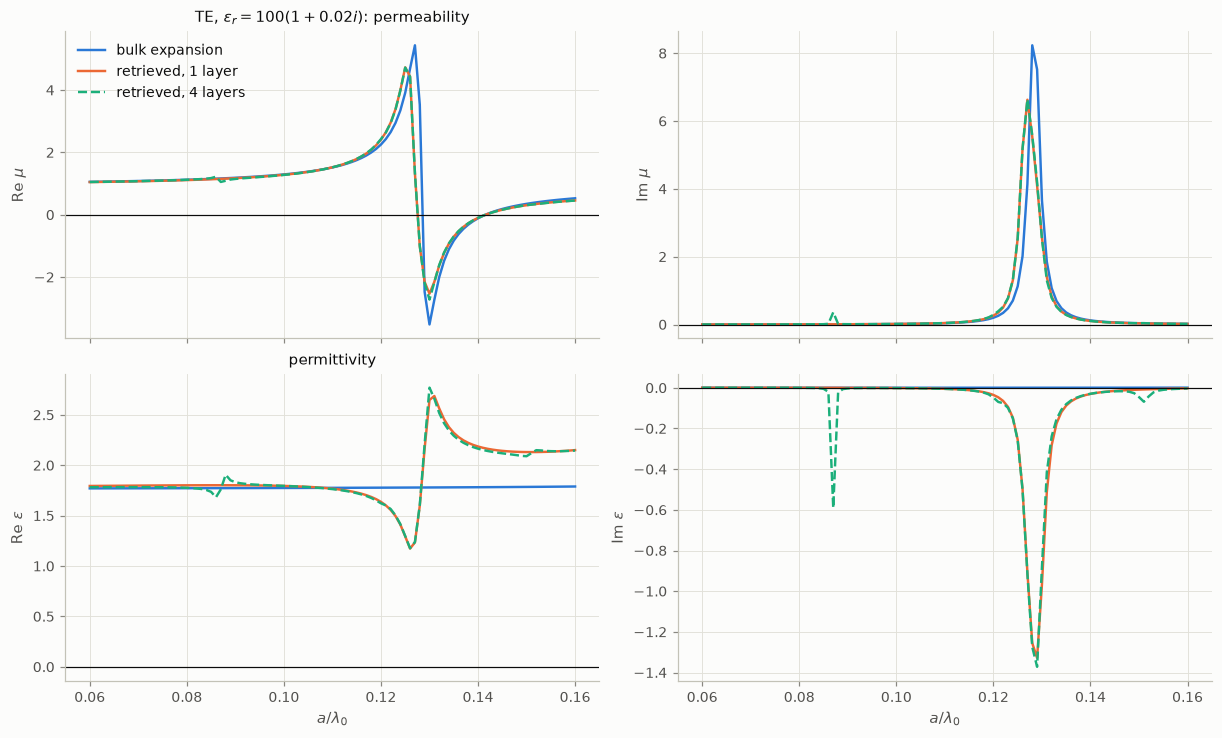

retrieved permittivity (1 layer): most negative imaginary part -1.328 at f = 0.1290; real part between 1.173 and 2.688
bulk permittivity over the same range: real part 1.7708 to 1.7894, imaginary part 0.00043 to 0.00078
imaginary part of mu, largest value: bulk 8.23, retrieved 6.63
PASS  the retrieved permittivity has a negative imaginary part near the resonance: got -1.32785, target -0.9, |diff| 4.28e-01 <= 6e-01
PASS  the bulk permittivity is passive (smallest imaginary part): got 0.000430547, target 0.0005, |diff| 6.95e-05 <= 5e-04
PASS  the bulk permittivity is featureless (relative variation of its real part over the sweep): got 0.010515, target 0, |diff| 1.05e-02 <= 2e-02
|n_ret(4 layers) - n_Bloch|: up to 0.0029 where Im n < 1, up to 0.074 in the strongly attenuating range
PASS  both describe the same index where Im n < 1 (largest |n_ret(4 layers) - n_Bloch|): got 0.00294368, target 0, |diff| 2.94e-03 <= 2e-02


In [6]:
EPS_L = 100.0 * (1 + 0.02j)
FTE = np.linspace(0.06, 0.16, 101)
t0 = time.perf_counter()
te = []
for f in FTE:
    k0 = TWO_PI * f
    eb, mb = bulk_parameters("TE", f, EPS_L)
    nb, yb = bulk_ny("TE", eb, mb)
    nB = bloch_index("TE", f, EPS_L, nb)
    nB = nb if not np.isfinite(nB) else nB
    r1 = retrieve(*rl.slab(k0, 0.0, 1, R, EPS_L, "TE", M=5)[:2], k0, 1, "TE", nB)
    r4 = retrieve(*rl.slab(k0, 0.0, 4, R, EPS_L, "TE", M=5)[:2], k0, 4, "TE", nB)
    r8, t8 = rl.slab(k0, 0.0, 8, R, EPS_L, "TE", M=5)[:2]
    te.append(dict(f=f, eb=eb, mb=mb, nb=nb, yb=yb, nB=nB, r1=r1, r4=r4, r8=abs(r8), t8=abs(t8),
                   r8_bulk=abs(homog_slab(k0, 8.0, nb, yb)[0]), r8_ret=abs(homog_slab(k0, 8.0, r1[0], r1[1])[0])))
print(f"sweep of {len(FTE)} frequencies: {time.perf_counter() - t0:.0f} s")
tcol = lambda key: np.array([row[key] for row in te])
absorbed = 1 - tcol("r8") ** 2 - tcol("t8") ** 2
print(f"absorption of the 8-layer slab, 1 - |r|^2 - |t|^2: between {absorbed.min():.4f} and {absorbed.max():.3f}")
assert (absorbed > 0).all(), "a lossy slab absorbs"
e1, m1 = np.array([row["r1"][2] for row in te]), np.array([row["r1"][3] for row in te])
e4, m4 = np.array([row["r4"][2] for row in te]), np.array([row["r4"][3] for row in te])

fig, axs = plt.subplots(2, 2, figsize=(11, 6.6), sharex=True)
for ax, q_bulk, q1, q4, part, name in ((axs[0, 0], tcol("mb"), m1, m4, np.real, r"Re $\mu$"), (axs[0, 1], tcol("mb"), m1, m4, np.imag, r"Im $\mu$"),
                                       (axs[1, 0], tcol("eb"), e1, e4, np.real, r"Re $\varepsilon$"), (axs[1, 1], tcol("eb"), e1, e4, np.imag, r"Im $\varepsilon$")):
    ax.plot(FTE, part(q_bulk), color=CAT[0], label="bulk expansion")
    ax.plot(FTE, part(q1), color=CAT[1], label="retrieved, 1 layer")
    ax.plot(FTE, part(q4), color=CAT[2], ls="--", label="retrieved, 4 layers")
    ax.axhline(0, color=INK, lw=0.8)
    ax.set(ylabel=name)
axs[0, 0].set_title(r"TE, $\varepsilon_r=100(1+0.02i)$: permeability"); axs[1, 0].set_title("permittivity")
axs[0, 0].legend(loc="upper left"); axs[1, 0].set_xlabel(r"$a/\lambda_0$"); axs[1, 1].set_xlabel(r"$a/\lambda_0$")
plt.show()

i_min = np.argmin(e1.imag)
print(f"retrieved permittivity (1 layer): most negative imaginary part {e1.imag.min():.3f} at f = {FTE[i_min]:.4f}; real part between {e1.real.min():.3f} and {e1.real.max():.3f}")
print(f"bulk permittivity over the same range: real part {tcol('eb').real.min():.4f} to {tcol('eb').real.max():.4f}, imaginary part {tcol('eb').imag.min():.5f} to {tcol('eb').imag.max():.5f}")
print(f"imaginary part of mu, largest value: bulk {tcol('mb').imag.max():.2f}, retrieved {m1.imag.max():.2f}")
check("the retrieved permittivity has a negative imaginary part near the resonance", e1.imag.min(), 0.6, -0.9)
check("the bulk permittivity is passive (smallest imaginary part)", tcol("eb").imag.min(), 5e-4, 5e-4)
check("the bulk permittivity is featureless (relative variation of its real part over the sweep)", tcol("eb").real.max() / tcol("eb").real.min() - 1, 0.02)
dn = np.abs(np.array([row["r4"][0] for row in te]) - tcol("nB"))
weak = tcol("nB").imag < 1.0                              # where four layers still transmit measurably
print(f"|n_ret(4 layers) - n_Bloch|: up to {dn[weak].max():.4f} where Im n < 1, up to {dn.max():.3f} in the strongly attenuating range")
check("both describe the same index where Im n < 1 (largest |n_ret(4 layers) - n_Bloch|)", dn[weak].max(), 0.02)
assert (m1.imag > -1e-6).all() and (tcol("mb").imag > 0).all()

The bulk permittivity does not notice the magnetic resonance: it is the Maxwell-Garnett-like constant of the lattice with a small positive imaginary part. The retrieved permittivity dips, recovers and overshoots through the resonance, and its imaginary part is negative across it, which for a passive material would be a sign of gain. Nothing is wrong with the slab or the retrieval: the retrieved index is the Bloch index wherever the slab transmits measurably, and $\operatorname{Im}\mu$ stays positive. This is the "antiresonance" of Koschny and coworkers, found here with an exact solver and with a bulk calculation next to it that shows no trace of it. It is a property of the admittance of the terminated lattice and not of the response of the medium to fields.

The retrieved curves from one layer and from four coincide on the scale of the figure except in two narrow intervals, near $a/\lambda_0=0.087$ and $0.15$. Those are the frequencies at which the four-layer slab is half a wavelength thick and hardly reflects. The inversion divides by the reflection there and amplifies the small surface correction of section 6, a known hazard of retrieval from thick slabs and no property of the lattice. Elsewhere the retrieved parameters do not depend on thickness, so in the sense of predicting other thicknesses they are the useful ones. The next figure makes that test, and the reverse one for the bulk parameters.

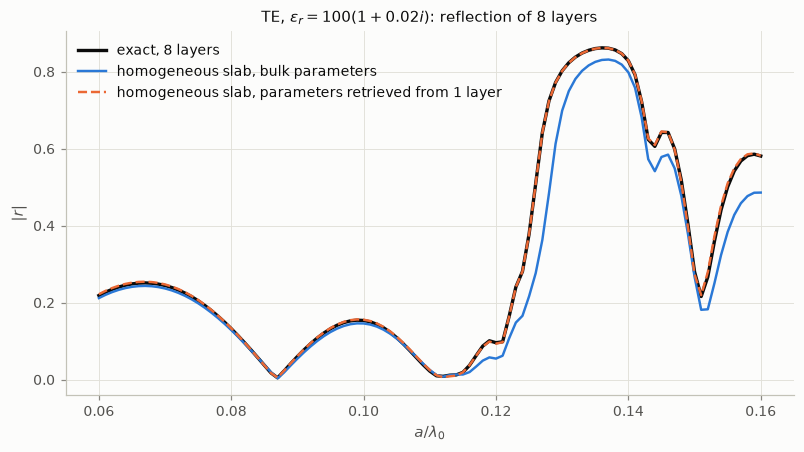

largest error of |r|: bulk parameters 0.279 at f = 0.1270 (exact 0.642), one-layer parameters 0.013
between f = 0.118 and 0.127 the bulk parameters give 0.54 to 0.65 of the exact |r|
PASS  one-layer parameters predict eight layers: got 0.0129003, target 0, |diff| 1.29e-02 <= 3e-02
PASS  bulk parameters miss the reflection near the resonance by more than 0.2: got 0.27869, target 0.4, |diff| 1.21e-01 <= 2e-01


In [7]:
fig, ax = plt.subplots(figsize=(7.2, 4))
ax.plot(FTE, tcol("r8"), color=INK, lw=2.2, label="exact, 8 layers")
ax.plot(FTE, tcol("r8_bulk"), color=CAT[0], label="homogeneous slab, bulk parameters")
ax.plot(FTE, tcol("r8_ret"), color=CAT[1], ls="--", label="homogeneous slab, parameters retrieved from 1 layer")
ax.set(xlabel=r"$a/\lambda_0$", ylabel=r"$|r|$", title=r"TE, $\varepsilon_r=100(1+0.02i)$: reflection of 8 layers"); ax.legend(loc="upper left")
plt.show()
below = FTE < 0.127
err_b, err_r = np.abs(tcol("r8_bulk") - tcol("r8")), np.abs(tcol("r8_ret") - tcol("r8"))
i_b = np.argmax(err_b)
print(f"largest error of |r|: bulk parameters {err_b.max():.3f} at f = {FTE[i_b]:.4f} (exact {tcol('r8')[i_b]:.3f}), one-layer parameters {err_r.max():.3f}")
ratio = tcol("r8_bulk")[below & (FTE > 0.118)] / tcol("r8")[below & (FTE > 0.118)]
print(f"between f = 0.118 and 0.127 the bulk parameters give {ratio.min():.2f} to {ratio.max():.2f} of the exact |r|")
check("one-layer parameters predict eight layers", err_r.max(), 0.03)
check("bulk parameters miss the reflection near the resonance by more than 0.2", err_b.max(), 0.2, 0.4)

## 5. One picture: the Bloch impedance against $qa$

Both findings are the same mechanism. Compare the wave impedance $z=E/H$ of a single layer (the Bloch impedance at the cell boundary) with the bulk value $\sqrt{\mu/\varepsilon}$, as a function of the Bloch phase $qa$, for lossless rods on the first band. In the lumped limit a cell whose electric response sits at its center is a T section, with $z_B=z\cos(qa/2)$, and a cell whose magnetic response sits at its center is a $\Pi$ section, with $z_B=z/\cos(qa/2)$.

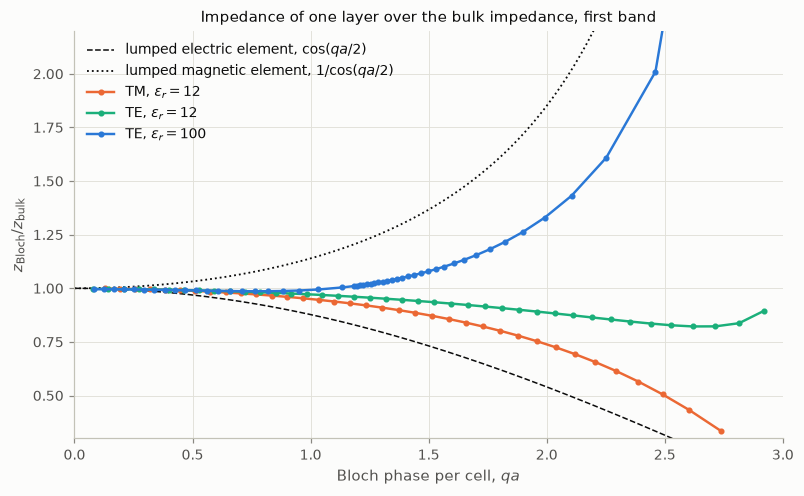

TM, eps_r = 12: ratio 0.9993 at qa = 0.13; 0.910 at qa = 1.30; 0.335 at qa = 2.74 (f = 0.1850)
TE, eps_r = 12: ratio 0.9971 at qa = 0.08; 0.946 at qa = 1.39; 0.896 at qa = 2.92 (f = 0.3200)
TE, eps_r = 100: ratio 0.9961 at qa = 0.08; 1.019 at qa = 1.24; 4.605 at qa = 2.86 (f = 0.1262)
TE, eps_r = 100: the ratio crosses 1 at qa = 1.13, f = 0.1100, and rises to 4.61
PASS  TE, eps_r = 100: below 1 off resonance, above 1 and below the lumped magnetic limit near it: got 1, target 1, |diff| 0.00e+00 <= 0e+00


In [8]:
def impedance_ratio(pol, eps, F):
    out = []
    for f in F:
        k0 = TWO_PI * f
        eb, mb = bulk_parameters(pol, f, eps, rho=0.1 if eps > 50 else 0.2)
        nb, yb = bulk_ny(pol, eb, mb)
        nB = bloch_index(pol, f, eps, nb)
        if not np.isfinite(nB) or abs(nB.imag) > 1e-6 or nb.imag > 1e-6:
            continue
        y1 = retrieve(*rl.slab(k0, 0.0, 1, R, eps, pol, M=5)[:2], k0, 1, pol, nB)[1]
        zr = (yb / y1).real if pol == "TM" else (y1 / yb).real
        out.append((nB.real * k0, zr, f))
    return np.array(out)


curves = {("TM", 12.0): impedance_ratio("TM", 12.0, np.linspace(0.01, 0.185, 36)),
          ("TE", 12.0): impedance_ratio("TE", 12.0, np.linspace(0.01, 0.32, 40)),
          ("TE", 100.0): impedance_ratio("TE", 100.0, np.concatenate([np.linspace(0.01, 0.11, 21), np.linspace(0.112, 0.1262, 30)]))}
fig, ax = plt.subplots(figsize=(7.2, 4.4))
qq = np.linspace(0, 2.9, 200)
ax.plot(qq, np.cos(qq / 2), color=INK, ls="--", lw=1, label=r"lumped electric element, $\cos(qa/2)$")
ax.plot(qq, 1 / np.cos(qq / 2), color=INK, ls=":", lw=1.2, label=r"lumped magnetic element, $1/\cos(qa/2)$")
for (pol, eps), colr in zip(curves, (CAT[1], CAT[2], CAT[0])):
    c = curves[(pol, eps)]
    ax.plot(c[:, 0], c[:, 1], "o-", ms=3, color=colr, label=rf"{pol}, $\varepsilon_r={eps:g}$")
ax.set(xlabel=r"Bloch phase per cell, $qa$", ylabel=r"$z_{\rm Bloch}/z_{\rm bulk}$", ylim=(0.3, 2.2), xlim=(0, 3.0),
       title="Impedance of one layer over the bulk impedance, first band")
ax.legend(loc="upper left")
plt.show()

for key, c in curves.items():
    print(f"{key[0]}, eps_r = {key[1]:g}: ratio {c[0, 1]:.4f} at qa = {c[0, 0]:.2f}; {c[len(c) // 2, 1]:.3f} at qa = {c[len(c) // 2, 0]:.2f}; {c[-1, 1]:.3f} at qa = {c[-1, 0]:.2f} (f = {c[-1, 2]:.4f})")
ctm, cte12, cte100 = curves[("TM", 12.0)], curves[("TE", 12.0)], curves[("TE", 100.0)]
assert ((ctm[:, 1] < 1) & (ctm[:, 1] > np.cos(ctm[:, 0] / 2) - 1e-9)).all(), "TM lies between 1 and the lumped electric limit"
assert (cte12[cte12[:, 0] > 0.5, 1] < 1).all(), "TE, eps_r = 12, lies below 1 on the first band"
i_cross = np.argmax(cte100[:, 1] > 1)
print(f"TE, eps_r = 100: the ratio crosses 1 at qa = {cte100[i_cross, 0]:.2f}, f = {cte100[i_cross, 2]:.4f}, and rises to {cte100[-1, 1]:.2f}")
check("TE, eps_r = 100: below 1 off resonance, above 1 and below the lumped magnetic limit near it",
      float((cte100[:i_cross, 1] < 1).all() and (cte100[i_cross:, 1] > 1).all() and (cte100[i_cross:, 1] < 1 / np.cos(cte100[i_cross:, 0] / 2)).all()), 0, 1.0)

Where the rods act mainly as an electric polarizability (TM throughout, TE with $\varepsilon_r=12$ on the first band, TE with $\varepsilon_r=100$ far below resonance) the impedance of the layer falls below the bulk value, toward the T-section curve. In $(\varepsilon,\mu)$ terms the retrieved permittivity is too large and the retrieved permeability too small: the diamagnetism of section 3. Where the rods act as magnetic resonators (TE with $\varepsilon_r=100$ approaching the resonance) the ratio turns around and rises toward the $\Pi$-section curve: the retrieved permeability is too large and the retrieved permittivity too small, which is the antiresonance of section 4. The lumped curves are limits, not fits; the rods fill a good part of the cell.

The departure is governed by $qa$, the phase of the Bloch wave across one cell, not by $a/\lambda_0$. A permeability resonance drives $q$ up, so the departure is largest exactly where $\mu$ is large, at any ratio of period to vacuum wavelength.

## 6. TE at low frequency: a surface layer

One more effect is visible in TE and absent in TM. At a frequency so low that $(qa)^2$ is negligible, the retrieved parameters of thin slabs still differ from the bulk ones, by an amount proportional to $1/N$.

TE, eps_r = 12: retrieved eps for N = [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(6), np.int64(8)]: [1.63931 1.63486 1.63337 1.63262 1.63186 1.63146]
      extrapolated to 1/N = 0: eps = 1.63037 (bulk 1.63016), mu = 0.99999 (bulk 1.00012); slope of eps in 1/N: +0.00895
TE, eps_r = 100: retrieved eps for N = [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(6), np.int64(8)]: [1.78233 1.77575 1.77355 1.77244 1.77132 1.77074]
      extrapolated to 1/N = 0: eps = 1.76912 (bulk 1.76886), mu = 1.00108 (bulk 1.00123); slope of eps in 1/N: +0.01323
TM, eps_r = 12: retrieved eps for N = [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(6), np.int64(8)]: [4.11497 4.11498 4.11498 4.11498 4.11498 4.11499]
      extrapolated to 1/N = 0: eps = 4.11499 (bulk 4.11191), mu = 0.99925 (bulk 1.00000); slope of eps in 1/N: -0.00002
PASS  TE, eps_r = 12: eps extrapolates to the bulk value: got 1.63037, target 1.63016, |diff| 2.08e-04 <= 3e-04
PASS  TE, eps_r = 12: m

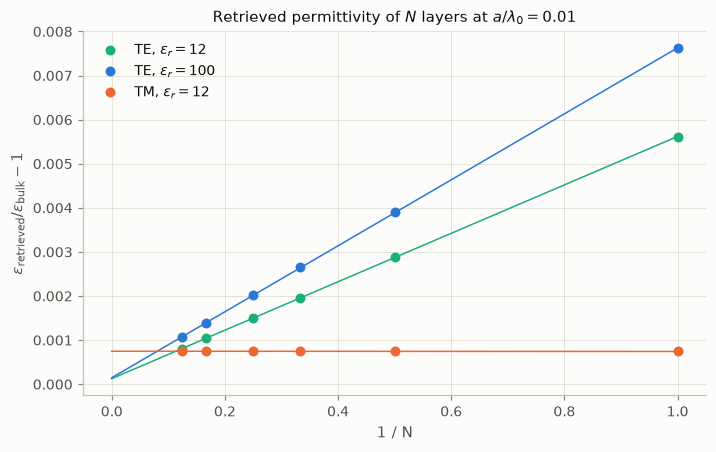

In [9]:
f_low = 0.01
k0 = TWO_PI * f_low
NS = np.array([1, 2, 3, 4, 6, 8])
layer = {}
for pol, eps in (("TE", 12.0), ("TE", 100.0), ("TM", 12.0)):
    eb, mb = bulk_parameters(pol, f_low, eps)
    nb, yb = bulk_ny(pol, eb, mb)
    nB = bloch_index(pol, f_low, eps, nb)
    ret = np.array([retrieve(*rl.slab(k0, 0.0, int(N), R, eps, pol, M=6)[:2], k0, N, pol, nB)[2:] for N in NS]).real
    fit_e, fit_m = np.polyfit(1 / NS, ret[:, 0], 1), np.polyfit(1 / NS, ret[:, 1], 1)      # value = slope / N + intercept
    layer[(pol, eps)] = (ret, fit_e, fit_m, eb.real, mb.real)
    print(f"{pol}, eps_r = {eps:g}: retrieved eps for N = {list(NS)}: {np.round(ret[:, 0], 5)}")
    print(f"      extrapolated to 1/N = 0: eps = {fit_e[1]:.5f} (bulk {eb.real:.5f}), mu = {fit_m[1]:.5f} (bulk {mb.real:.5f}); slope of eps in 1/N: {fit_e[0]:+.5f}")
for key in (("TE", 12.0), ("TE", 100.0)):
    ret, fit_e, fit_m, eb, mb = layer[key]
    check(f"{key[0]}, eps_r = {key[1]:g}: eps extrapolates to the bulk value", fit_e[1], 3e-4, eb)
    check(f"{key[0]}, eps_r = {key[1]:g}: mu extrapolates to the bulk value", fit_m[1], 3e-4, mb)
    check(f"{key[0]}, eps_r = {key[1]:g}: the correction is linear in 1/N (rms residual of the fit)", np.sqrt(np.mean((ret[:, 0] - np.polyval(fit_e, 1 / NS)) ** 2)), 1e-4)
check("TM: no 1/N term (slope of eps, relative to eps)", layer[("TM", 12.0)][1][0] / layer[("TM", 12.0)][3], 1e-3)

fig, ax = plt.subplots()
for key, colr in zip((("TE", 12.0), ("TE", 100.0), ("TM", 12.0)), (CAT[2], CAT[0], CAT[1])):
    ret, fit_e, fit_m, eb, mb = layer[key]
    ax.plot(1 / NS, ret[:, 0] / eb - 1, "o", color=colr, label=rf"{key[0]}, $\varepsilon_r={key[1]:g}$")
    ax.plot([0, 1], np.polyval(fit_e, [0, 1]) / eb - 1, color=colr, lw=1)
ax.set(xlabel="1 / N", ylabel=r"$\varepsilon_{\rm retrieved}/\varepsilon_{\rm bulk}-1$", title=rf"Retrieved permittivity of $N$ layers at $a/\lambda_0={f_low}$"); ax.legend(loc="upper left")
plt.show()

In TE a single layer of rods has a permittivity a little under one percent above the bulk value even in the static limit, and the excess falls like $1/N$: it is a fixed surface contribution. The rods polarize each other through their near fields, the rods in the outermost rows have neighbors on one side only, and their polarization differs from that of the rows inside. Extrapolated to $1/N\to0$ the retrieved $\varepsilon$ is the bulk value of notebook 03 to the printed accuracy, which is the one regime in which the bulk parameters with ordinary boundary conditions are simply right: long wavelength in the lattice and a thick slab. For $\mu$ the test is weak: the extrapolated and bulk values agree to about $10^{-4}$, which is the size of $\mu-1$ itself at this frequency for $\varepsilon_r=12$ and an eighth of it for $\varepsilon_r=100$. In TM there is no such term, because a static field along the rods is uniform and the rods do not interact.

So a slab differs from "bulk parameters plus Fresnel" in two ways: a surface layer, static in origin and proportional to $1/N$ in a retrieval, and the $(qa)^2$ departure of the Bloch impedance, which does not go away with thickness. Drude's transition layers and Simovski's Bloch material parameters are the names under which the two appear in the literature.

## Summary

- **Index.** The retrieved index converges to the Bloch index of the bulk calculation with thickness; one layer is within a few parts in a thousand in the cases printed.
- **Three permeabilities.** For TM at low frequency: positive from the rod's magnetic dipole, zero at order $\omega^2$ from the bulk expansion, negative from the slab. The slab's value predicts slabs; the bulk's value is the response of the medium to fields.
- **Antiresonance.** For TE through the magnetic resonance with lossy rods the retrieved permittivity has a resonant feature with a negative imaginary part. The bulk permittivity has no feature and is passive. Bulk parameters with Fresnel boundary conditions give little more than half of the reflection just below the resonance.
- **Mechanism.** The Bloch impedance at the cell boundary differs from the bulk impedance at order $(qa)^2$, downward for a concentrated electric response and upward for a concentrated magnetic one. A resonance of $\mu$ makes $qa$ large, so the departure peaks there.
- **Surface layer.** In TE thin slabs carry a static surface term, proportional to $1/N$; the extrapolated permittivity is the bulk one (the permeability is too close to one at that frequency for the test to say much).

What this says about optical magnetism in this structure: the permeability is a correct and economical statement about the bulk response, to second order in $ka$, in one polarization, near resonance and at high rod permittivity (notebook 03). The number a slab returns under the name $\mu$ is a different quantity that mixes this response with the periodicity. Both are legitimate; they answer different questions, and only the index is common to them.

## Caveats and open ends

- Normal incidence along a lattice axis only. At oblique incidence a local description needs the same parameters at every angle, and the anisotropy $\delta$ of notebook 03 says they will not be; this was not computed. Slabs cut along $\Gamma M$ were not studied either.
- One termination. The rods cannot be cut, so the dependence on termination is shown for the one-dimensional stack of notebook 01 and inferred here from the sign and the $(qa)^2$ law.
- The semi-infinite lattice was not solved. "Bloch impedance" here is the impedance of a single layer, which includes the surface term of section 6; the two effects were separated only at low frequency.
- No additional boundary conditions were derived. A nonlocal description with the full $\varepsilon(\omega,\mathbf k)$ and a suitable boundary condition should reproduce the slab; finding that condition for this lattice is open.
- Finite bodies (a cylinder cut from the lattice, the natural object for the scattering testbed of this project) were not computed. The cluster solver in `rodlattice.py` is there for it.

## References

- D. R. Smith, S. Schultz, P. Markoš and C. M. Soukoulis, Phys. Rev. B 65, 195104 (2002), retrieval from reflection and transmission.
- T. Koschny, P. Markoš, D. R. Smith and C. M. Soukoulis, Phys. Rev. E 68, 065602 (2003), antiresonances; T. Koschny et al., Phys. Rev. B 71, 245105 (2005), the role of periodicity.
- C. R. Simovski, Metamaterials 1, 62 (2007); C. R. Simovski and S. A. Tretyakov, Phys. Rev. B 75, 195111 (2007), Bloch parameters and transition layers.
- A. Alù, Phys. Rev. B 84, 075153 (2011).
- M. G. Silveirinha, Phys. Rev. B 75, 115104 (2007).
- V. A. Markel and J. C. Schotland, Phys. Rev. E 85, 066603 (2012), homogenization of periodic composites with the reflection of a half-space computed explicitly.
- J. Skaar, H. O. Hågenvik and C. A. Dirdal, Phys. Rev. B 99, 064407 (2019), four definitions of the permeability compared.